# Sri Lankan Vehicle Listing Price Prediction
Training-only exploration, expanded tabular model comparison, interpretation and inference. Values are in lakhs unless labelled LKR. The existing test split is exploratory.

In [ ]:
# Sri Lankan Vehicle Listing Price Prediction
# Author: Sithum Wickramanayaka
# Degree: MSc in Artificial Intelligence
# University: University of Moratuwa
# Student ID: 269214N
# Batch: 19
# Module: IT5514 - Applied Machine Learning


In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image, Markdown
from src.data import load_data, split_data, FEATURES
df, audit = load_data()
train, test, demo, cutoff, purged = split_data(df)
display(pd.Series(audit))
display(train.head())

raw_rows                                                                       9788
clean_rows                                                                     9770
invalid_rows                                                                      0
duplicates_removed                                                               18
missing_raw                       {'Unnamed: 0': 0, 'Brand': 0, 'Model': 0, 'YOM...
mileage_formula_match_fraction                                                  1.0
date_min                                                                 2024-12-03
date_max                                                                 2025-02-05
price_unit                                               LKR lakhs (user-confirmed)
dtype: object

,Unnamed: 0,brand,model,year,engine_cc,gear,fuel,Millage(KM),town,date,leasing,condition,air_condition,power_steering,power_mirror,power_window,price,row_id,group
0,1253,HYUNDAI,GRAND I10,2016,1000.0,AUTOMATIC,PETROL,99000.0,BATTARAMULLA,2024-12-03,NO LEASING,USED,AVAILABLE,AVAILABLE,AVAILABLE,AVAILABLE,58.0,1253,14076929561589658937
1,71,AUSTIN,MINI COOPER,1969,1300.0,AUTOMATIC,PETROL,616000.0,MATARA,2024-12-04,NO LEASING,USED,AVAILABLE,NOT_AVAILABLE,NOT_AVAILABLE,NOT_AVAILABLE,28.5,71,17048167182074652515
2,136,BMW,730IL,2011,3000.0,AUTOMATIC,PETROL,154000.0,COLOMBO,2024-12-04,NO LEASING,USED,AVAILABLE,AVAILABLE,AVAILABLE,AVAILABLE,275.0,136,5941692083290413260
3,199,CHERY,QQ,2009,800.0,MANUAL,PETROL,176000.0,HANWELLA,2024-12-04,NO LEASING,USED,AVAILABLE,AVAILABLE,AVAILABLE,AVAILABLE,15.0,199,5036400770552479301
4,208,CHEVROLET,BEAT,2011,1200.0,MANUAL,PETROL,154000.0,KIRIBATHGODA,2024-12-04,NO LEASING,USED,AVAILABLE,AVAILABLE,NOT_AVAILABLE,AVAILABLE,27.5,208,12251886823049489646


## Training-only exploration and candidate rationale

,Unnamed: 0,year,engine_cc,price
0,count,5285.000000,5285.000000,5285.000000
1,mean,2006.503122,1269.753264,52.794914
2,std,10.083163,410.665589,43.628412
3,min,1956.000000,573.000000,3.250000
4,1%,1980.000000,650.000000,6.000000
5,50%,2009.000000,1300.000000,42.500000
6,90%,2017.000000,1790.000000,94.437500
7,95%,2018.000000,2000.000000,120.000000
8,99%,2019.000000,2400.000000,220.480000
9,max,2024.000000,4800.000000,790.000000


,feature,unique_values,categories_under_3_rows,rows_in_rare_categories
0,brand,48,14,18
1,model,1061,758,893
2,gear,2,0,0
3,fuel,4,0,0
4,town,106,6,6
5,leasing,2,0,0
6,condition,2,0,0
7,air_condition,2,0,0
8,power_steering,2,0,0
9,power_mirror,2,0,0


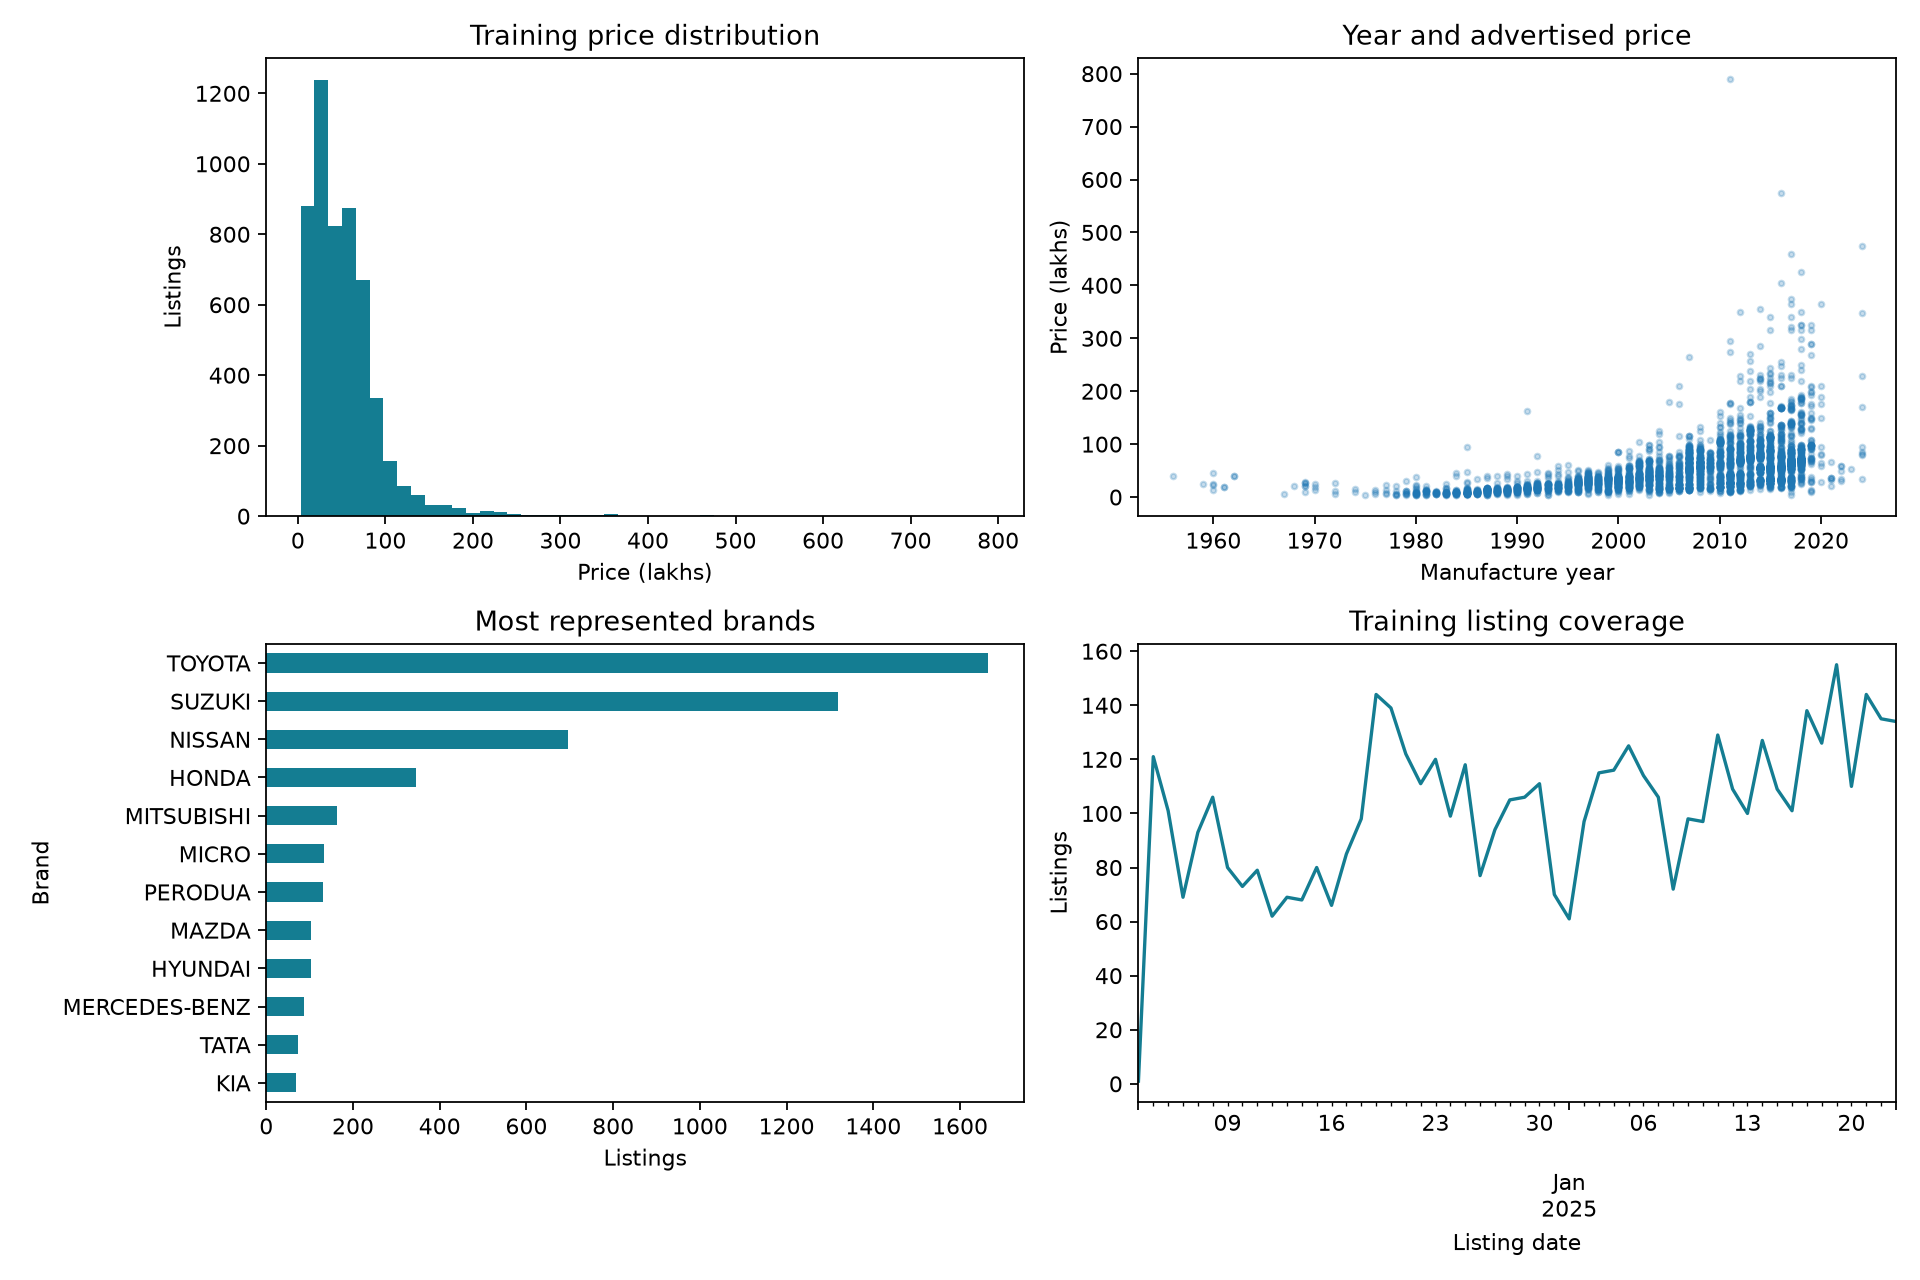

# Experiment plan

Prepared 14 October 2026, before running the expanded candidate comparison.

Problem: predict historical Sri Lankan advertised vehicle prices from tabular fields.
The study uses a fixed source dataset and temporal split to compare tabular regression approaches.

Training-only exploration shows 1,061 vehicle model labels, 758 occurring fewer
than three times, price skewness 3.80 and a median of 42.5 lakhs versus a maximum
of 790 lakhs. The year/price Spearman association is 0.65. These observations
motivate categorical-aware models, nonlinear candidates and scrutiny of tail errors.
They do not establish causality.

## Fixed evaluation decisions

- Preserve the established temporal split and purged feature groups; no random reshuffle.
- Compare Random Forest, XGBoost, CatBoost, LightGBM, Ridge and RF/XGBoost stacking.
- Include the training-median prediction as a non-deployable reference benchmark.
- Use three bounded configurations per standalone model. Do not expand the search
  after reading the new test results. Stacking retains its fixed base configurations.
- Select the smallest mean temporal validation MAE. Also report fold variation,
  test MAE/RMSE/R², runtime, errors by brand and actual-price band.
- Price-band boundaries: 0–25, 25–50, 50–100, 100–200 and above 200 lakhs.
- Keep extreme prices for evaluation; do not delete hard examples to improve scores.
- CatBoost uses native categorical handling. Other standalone models use
  fold-fitted imputation and one-hot encoding; Ridge additionally scales numeric inputs.
- No target encoding, preprocessing fit, parameter search or meta-model fitting
  may include validation/test target values outside its corresponding training partition.

## Evidence limits

The existing test set was inspected during earlier model and stacking development.
Expanded results are exploratory, even though the new selection uses validation
only. A truly independent confirmation needs newly collected future listings;
repartitioning these known rows would not make them unseen again. No claims of
statistical superiority or present-day valuation accuracy are made.


In [2]:
display(pd.read_csv(ROOT/'reports/data/numeric_profile.csv'))
display(pd.read_csv(ROOT/'reports/data/categorical_profile.csv'))
display(Image(filename=str(ROOT/'reports/figures/training_eda.png')))
display(Markdown((ROOT/'docs/experiment_plan.md').read_text()))

## Reproduce model fitting
Set RETRAIN=True to rerun the frozen search. No test-driven tuning.

In [3]:
RETRAIN=False
if RETRAIN:
    from scripts.analyze_data import main as analyze
    from src.train import main as train_models
    from scripts.summarize_results import main as summarize
    analyze()
    train_models()
    summarize()
display(pd.read_csv(ROOT/'reports/metrics/model_comparison.csv'))
display(pd.read_csv(ROOT/'reports/metrics/experiments.csv'))
display(pd.read_csv(ROOT/'reports/metrics/validation_folds.csv'))
display(pd.Series(json.loads((ROOT/'reports/metrics/baseline.json').read_text())))

,model,cv_mae,cv_std,training_seconds,parameters,test_mae,test_rmse,test_r2,prediction_ms_per_row,train_mae
0,Random Forest,7.148274,0.146047,7.707776,"{""model__max_depth"": 22, ""model__min_samples_l...",5.830394,14.440418,0.893138,0.011543,2.675995
1,Stacking,7.298925,0.248756,9.914533,"{""meta_model"": ""StandardScaler + Ridge"", ""alph...",6.474806,14.410682,0.893578,0.015119,4.778111
2,XGBoost,7.562429,0.311620,1.387915,"{""model__max_depth"": 7, ""model__n_estimators"":...",6.821414,14.240944,0.896070,0.004016,5.566662
3,CatBoost,8.740034,0.363583,4.273302,"{""model__depth"": 6, ""model__l2_leaf_reg"": 8}",8.414092,15.606161,0.875188,0.002195,7.761663
4,LightGBM,9.409556,0.229550,1.806861,"{""model__min_child_samples"": 20, ""model__num_l...",7.589768,15.282745,0.880308,0.006896,7.142192
5,Ridge,11.124350,0.670504,0.243644,"{""model__alpha"": 1}",9.993699,20.694404,0.780533,0.002102,9.230254


,model,parameters,cv_mae,cv_std
0,Random Forest,"{""model__max_depth"": 12, ""model__min_samples_l...",7.846810,0.421152
1,Random Forest,"{""model__max_depth"": 22, ""model__min_samples_l...",7.148274,0.146047
2,Random Forest,"{""model__max_depth"": 18, ""model__min_samples_l...",7.672327,0.211412
3,XGBoost,"{""model__max_depth"": 3, ""model__n_estimators"":...",8.832997,0.453671
4,XGBoost,"{""model__max_depth"": 5, ""model__n_estimators"":...",7.778316,0.361734
5,XGBoost,"{""model__max_depth"": 7, ""model__n_estimators"":...",7.562429,0.311620
6,CatBoost,"{""model__depth"": 4, ""model__l2_leaf_reg"": 5}",8.899647,0.462117
7,CatBoost,"{""model__depth"": 6, ""model__l2_leaf_reg"": 8}",8.740034,0.363583
8,CatBoost,"{""model__depth"": 8, ""model__l2_leaf_reg"": 10}",8.773815,0.233507
9,LightGBM,"{""model__min_child_samples"": 20, ""model__num_l...",9.409556,0.229550


,model,fold,mae
0,Random Forest,1,7.180831
1,Random Forest,2,6.955362
2,Random Forest,3,7.308629
3,XGBoost,1,7.513549
4,XGBoost,2,7.207570
5,XGBoost,3,7.966169
6,CatBoost,1,8.395788
7,CatBoost,2,8.581385
8,CatBoost,3,9.242929
9,LightGBM,1,9.720722


model        Training median
cv_mae             28.202153
test_mae           28.670441
test_rmse          45.657244
test_r2            -0.068276
dtype: object

## Justification and subgroup errors

In [4]:
display(Markdown((ROOT/'reports/interpretations/model_selection.md').read_text()))
display(pd.read_csv(ROOT/'reports/errors/errors_by_price_band.csv'))
display(pd.read_csv(ROOT/'reports/errors/errors_by_category_coverage.csv'))
display(Markdown((ROOT/'docs/related_work.md').read_text()))

### Model choice and evidence

**Random Forest** is selected because it has the lowest mean validation MAE
(**7.15 lakhs**) among the evaluated configurations. Test MAE is
**5.83 lakhs**, compared with **28.67** for a
training-median prediction (79.7% lower error on this historical split).
This demonstrates improvement over a simple local benchmark, not over external studies.

The training data has **1,061 model labels**, including **758** occurring fewer
than three times. Median training price is **42.5 lakhs** and
95th percentile **120.0 lakhs**. CatBoost tests native categorical
handling; LightGBM tests another efficient nonlinear approach; Ridge provides a
simpler additive reference. RF, XGBoost and stacking provide complementary ensemble comparisons.

Selection uses MAE because it measures average monetary error directly. RMSE
reveals the influence of large mistakes; R² is not percentage accuracy. Runtime
and fold variation are supporting evidence, not alternate post-hoc selection rules.
A more complex model is not automatically better. Error by actual-price band and
unseen model label must be considered before trusting an individual estimate.

**Limit:** this test split was already inspected during earlier development. Expanded results are
exploratory. Newly collected future listings are required for independent confirmation.
The source covers December 2024–February 2025; estimates are historical asking
prices rather than current valuations or verified sale prices.


,model,actual_price_band_lakhs,count,mae_lakhs,rmse_lakhs
0,Random Forest,0–25,938,3.983626,7.622923
1,Random Forest,25–50,1307,4.025102,7.911571
2,Random Forest,50–100,1467,5.240200,9.774451
3,Random Forest,100–200,299,12.406100,21.291873
4,Random Forest,>200,62,54.079792,83.983771
5,XGBoost,0–25,938,5.190510,9.362161
6,XGBoost,25–50,1307,4.983962,8.399987
7,XGBoost,50–100,1467,6.295256,10.749237
8,XGBoost,100–200,299,14.017876,21.792307
9,XGBoost,>200,62,47.974120,74.062163


,model,category,count,mae_lakhs
0,Random Forest,Seen model label,3484,4.829984
1,Random Forest,Unseen model label,589,11.747929
2,XGBoost,Seen model label,3484,5.993033
3,XGBoost,Unseen model label,589,11.721381
4,CatBoost,Seen model label,3484,7.664062
5,CatBoost,Unseen model label,589,12.850599
6,LightGBM,Seen model label,3484,6.760240
7,LightGBM,Unseen model label,589,12.496517
8,Ridge,Seen model label,3484,8.379421
9,Ridge,Unseen model label,589,19.542332


# Related approaches and comparison

Sources checked on 14 October 2026. This is a methodological comparison, not a
replication of published scores. Our controlled numerical comparisons use our
own identical training/validation/test partitions.

| Approach | Source evidence | Comparison with this project | Limit of the comparison |
|---|---|---|---|
| Sri Lankan used-car regression and averaging | Basnayaka (2023) compares linear regression, Random Forest, Extra Trees, gradient boosting, LightGBM and XGBoost, then averages predictions. | We evaluate related linear and tree families; retain RF/XGBoost stacking instead of simple averaging; audit synthetic mileage and use purged temporal evaluation. | The repository abstract reports “accuracy”; its metric and split are not sufficiently specified for numerical equivalence to our MAE/R². We do not claim to reproduce or outperform it. |
| CatBoost | Prokhorenkova et al. (2018) present ordered boosting and categorical-feature processing. | Native categorical input is relevant to our many rare vehicle model labels; encoding is fitted within training folds. | General benchmark results do not guarantee benefits for Sri Lankan vehicle listings. Our configuration uses the library's boosting default; we do not claim to reproduce the paper's experiments. |
| LightGBM | Ke et al. (2017) describe efficient gradient-boosted trees, including GOSS and feature bundling. | Histogram-based LightGBM is evaluated as an efficiency-oriented nonlinear candidate, with restricted leaves and minimum leaf counts. | Our ordinary GBDT configuration uses row subsampling, not a GOSS replication. Runtime is measured locally; published speedups are not transferred to this dataset. |
| Median and regularized linear references | Implemented here on the same splits. | Median establishes a no-feature error level; Ridge tests whether tree complexity improves on an additive relationship. | These are local benchmarks, not reproductions of the Sri Lankan study's linear model. |

## References

1. Basnayaka, D. (2023). [Prediction of Market Price for Used Cars in Sri Lanka Based on Machine Learning Approaches](https://dlib.iit.ac.lk/xmlui/handle/123456789/1634). IIT repository abstract.
2. Prokhorenkova, L., Gusev, G., Vorobev, A., Dorogush, A. V., and Gulin, A. (2018). [CatBoost: unbiased boosting with categorical features](https://arxiv.org/abs/1706.09516). NeurIPS.
3. Ke, G. et al. (2017). [LightGBM: A Highly Efficient Gradient Boosting Decision Tree](https://papers.nips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html). NeurIPS.
4. [CatBoost categorical-feature documentation](https://catboost.ai/docs/en/features/categorical-features). Supports using native categorical input rather than external one-hot encoding.
5. [LightGBM parameter-tuning documentation](https://lightgbm.readthedocs.io/en/v4.5.0/Parameters-Tuning.html). Supports constraining leaves and minimum observations to control complexity.


## Model-specific diagnostics and interpretations

### Random Forest: strengths and limitations

**Strengths.** Averages many trees to reduce prediction variance. Captures nonlinear relationships and interactions.

**Limitations.** Rare vehicles can have large errors. Cannot reliably extrapolate beyond training prices.

**Measured results.** Validation MAE: **7.15 lakhs**; test MAE: **5.83 lakhs**; test RMSE: **14.44 lakhs**; test R²: **0.893**. Training MAE was **2.68 lakhs**. Lower MAE/RMSE is better; higher R² is better. R² is unitless, not percentage accuracy.

**Feature-importance chart.** The strongest fields are **year, brand, gear, engine cc**, in that order. Longer bars mean shuffling that feature increased test error more. This is overall model reliance, not proof of causation, the direction of an effect, or an explanation for a single car. Correlated fields can share importance, and shuffling can produce unrealistic combinations.

**Actual-versus-predicted graph.** Points on the dashed diagonal are correct predictions. Points below it are underestimates; points above it are overestimates. Each point represents one unseen test listing.

**Residual graph.** Residual = actual price − predicted price. Positive values mean underestimation; negative values mean overestimation. A tight cloud around zero is desirable. The mean signed residual is **0.08 lakhs**; the largest absolute test error is **317.34 lakhs**. These describe the whole test set, not a guaranteed range for the current vehicle.

**What the graphs show here.** Most listings form a dense cluster at the lower end of the price range, broadly following the diagonal. The diagnostics show the direction and size of errors for this model. Points far from the diagonal or zero line identify large errors; no model is guaranteed reliable across all vehicles. The plots alone do not establish why those listings were difficult.

**Large-error interpretation.** RMSE (14.44) is much larger than MAE (5.83), consistent with some large errors having a strong effect on the squared-error metric. Inspect isolated points far from the diagonal/zero line; an average score can hide these failures.


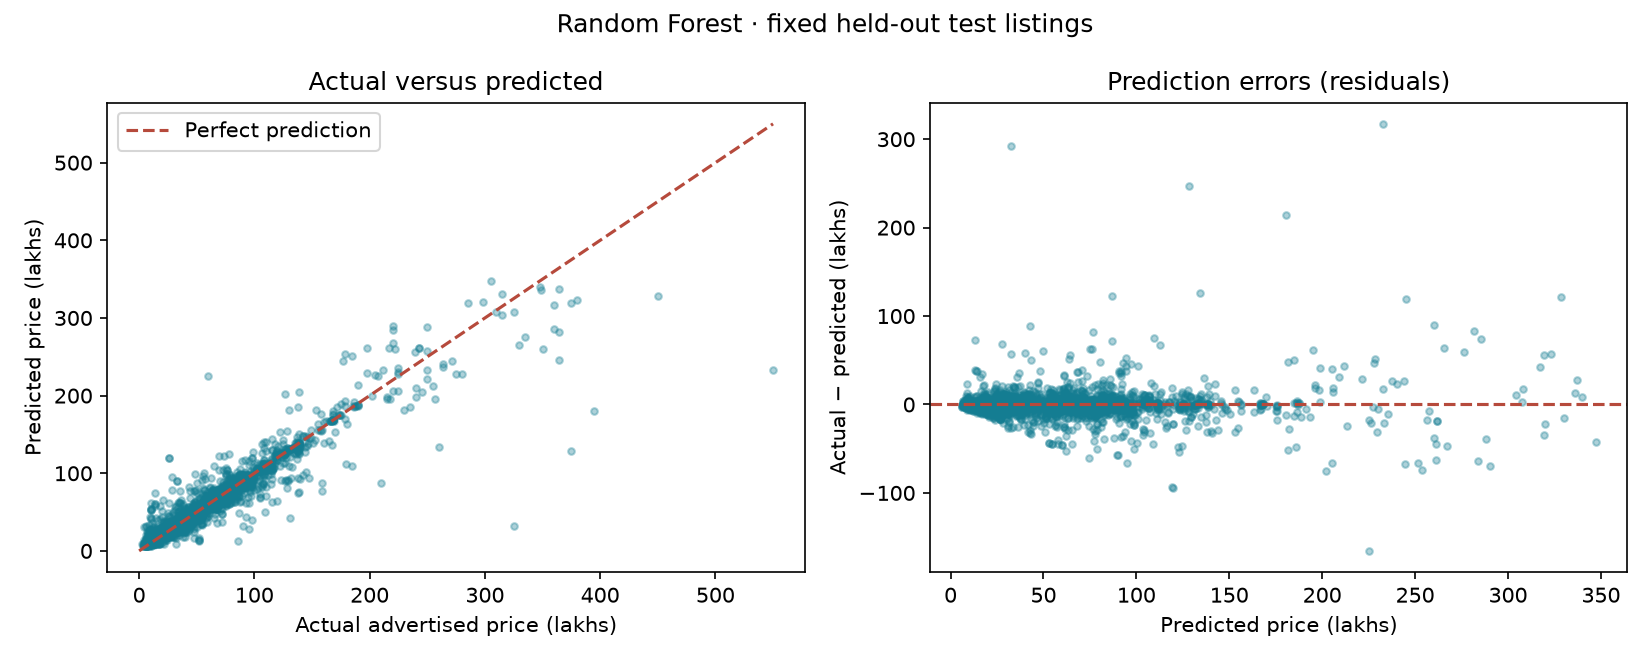

### XGBoost: strengths and limitations

**Strengths.** Successive trees correct earlier errors. Regularization controls complex nonlinear patterns.

**Limitations.** Sensitive to parameter choices. Rare categories and market changes can still cause large errors.

**Measured results.** Validation MAE: **7.56 lakhs**; test MAE: **6.82 lakhs**; test RMSE: **14.24 lakhs**; test R²: **0.896**. Training MAE was **5.57 lakhs**. Lower MAE/RMSE is better; higher R² is better. R² is unitless, not percentage accuracy.

**Feature-importance chart.** The strongest fields are **year, brand, engine cc, gear**, in that order. Longer bars mean shuffling that feature increased test error more. This is overall model reliance, not proof of causation, the direction of an effect, or an explanation for a single car. Correlated fields can share importance, and shuffling can produce unrealistic combinations.

**Actual-versus-predicted graph.** Points on the dashed diagonal are correct predictions. Points below it are underestimates; points above it are overestimates. Each point represents one unseen test listing.

**Residual graph.** Residual = actual price − predicted price. Positive values mean underestimation; negative values mean overestimation. A tight cloud around zero is desirable. The mean signed residual is **-0.24 lakhs**; the largest absolute test error is **294.56 lakhs**. These describe the whole test set, not a guaranteed range for the current vehicle.

**What the graphs show here.** Most listings form a dense cluster at the lower end of the price range, broadly following the diagonal. The diagnostics show the direction and size of errors for this model. Points far from the diagonal or zero line identify large errors; no model is guaranteed reliable across all vehicles. The plots alone do not establish why those listings were difficult.

**Large-error interpretation.** RMSE (14.24) is much larger than MAE (6.82), consistent with some large errors having a strong effect on the squared-error metric. Inspect isolated points far from the diagonal/zero line; an average score can hide these failures.


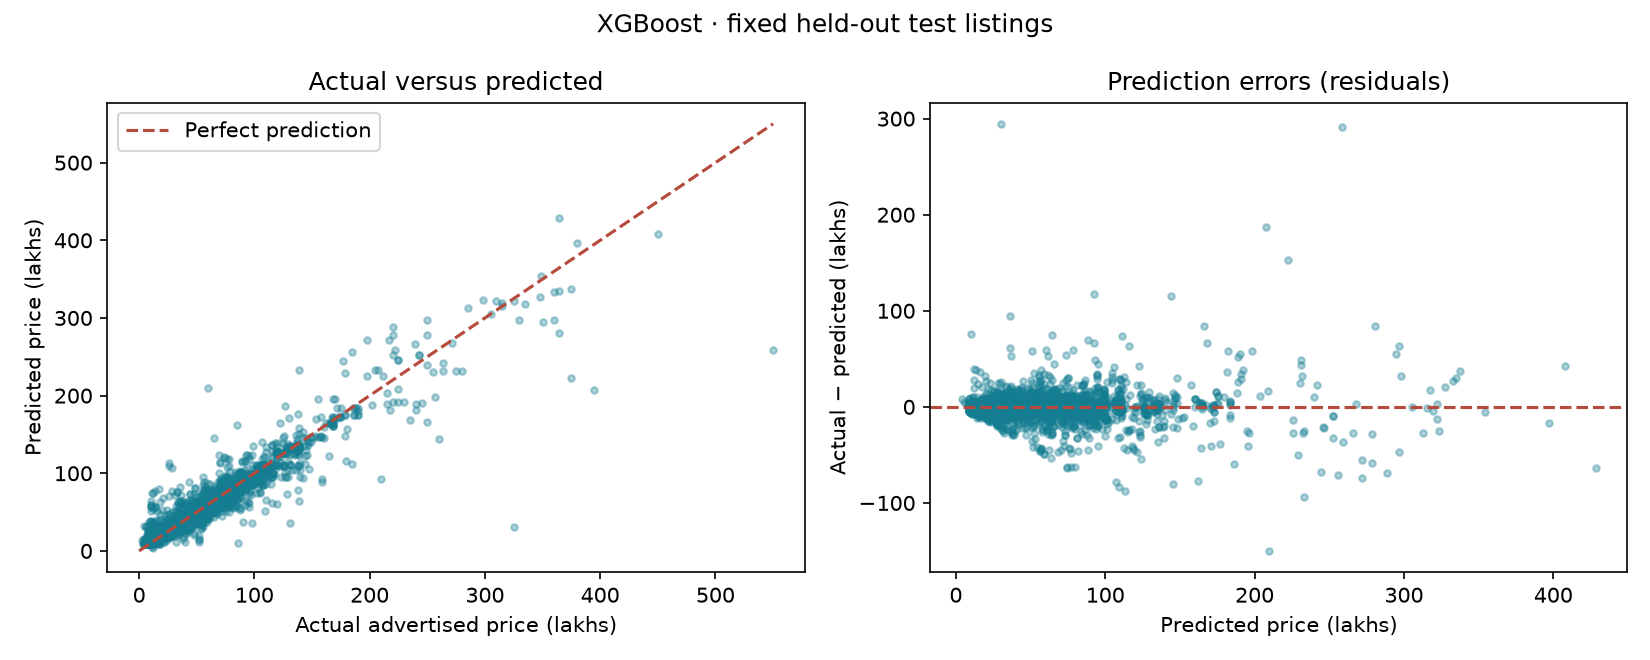

### CatBoost: strengths and limitations

**Strengths.** Uses categorical fields directly, without external one-hot encoding. Can capture patterns across many vehicle model categories.

**Limitations.** Rare categories still have limited supporting evidence. Categorical statistics must be learned inside training folds.

**Measured results.** Validation MAE: **8.74 lakhs**; test MAE: **8.41 lakhs**; test RMSE: **15.61 lakhs**; test R²: **0.875**. Training MAE was **7.76 lakhs**. Lower MAE/RMSE is better; higher R² is better. R² is unitless, not percentage accuracy.

**Feature-importance chart.** The strongest fields are **year, brand, engine cc, gear**, in that order. Longer bars mean shuffling that feature increased test error more. This is overall model reliance, not proof of causation, the direction of an effect, or an explanation for a single car. Correlated fields can share importance, and shuffling can produce unrealistic combinations.

**Actual-versus-predicted graph.** Points on the dashed diagonal are correct predictions. Points below it are underestimates; points above it are overestimates. Each point represents one unseen test listing.

**Residual graph.** Residual = actual price − predicted price. Positive values mean underestimation; negative values mean overestimation. A tight cloud around zero is desirable. The mean signed residual is **0.11 lakhs**; the largest absolute test error is **302.58 lakhs**. These describe the whole test set, not a guaranteed range for the current vehicle.

**What the graphs show here.** Most listings form a dense cluster at the lower end of the price range, broadly following the diagonal. The diagnostics show the direction and size of errors for this model. Points far from the diagonal or zero line identify large errors; no model is guaranteed reliable across all vehicles. The plots alone do not establish why those listings were difficult.

**Large-error interpretation.** RMSE (15.61) is much larger than MAE (8.41), consistent with some large errors having a strong effect on the squared-error metric. Inspect isolated points far from the diagonal/zero line; an average score can hide these failures.


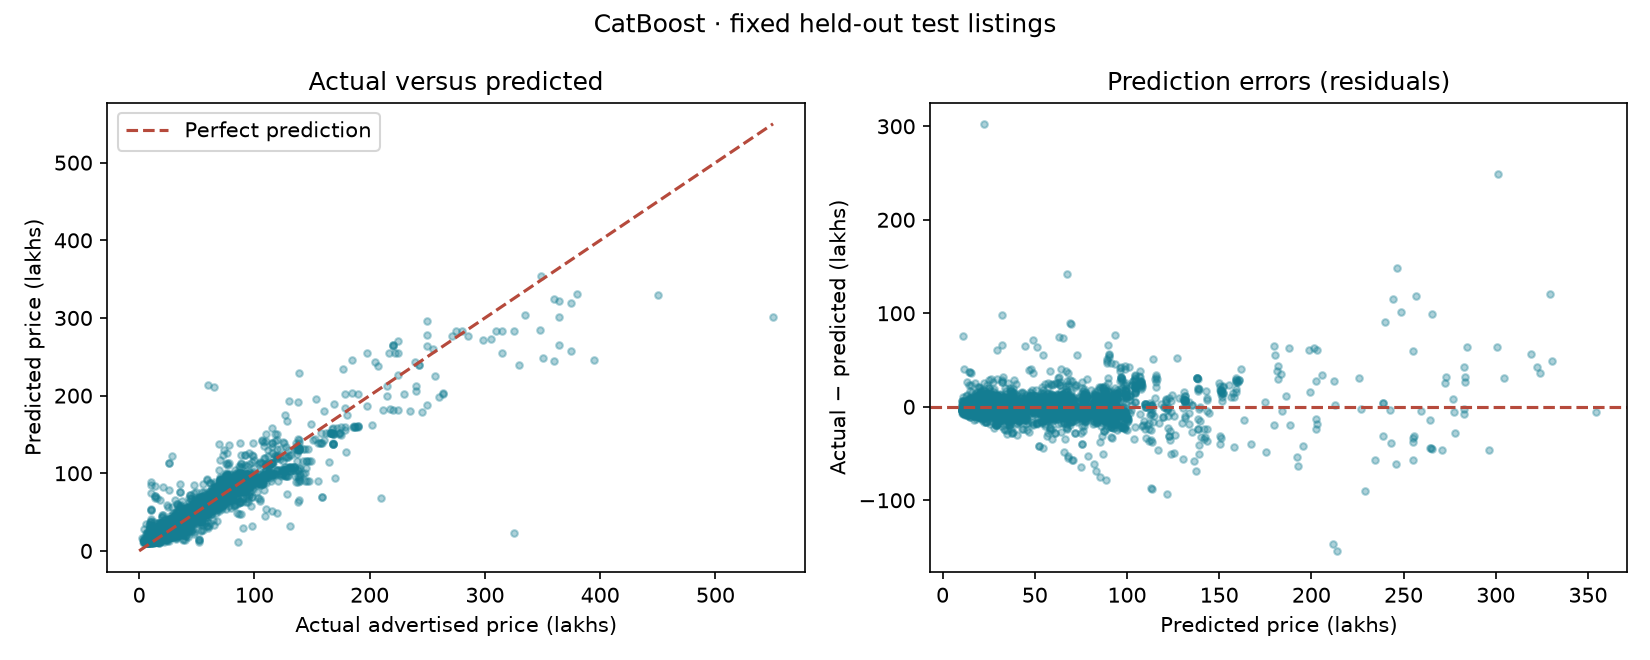

### LightGBM: strengths and limitations

**Strengths.** Histogram-based boosting is an efficient tabular candidate. Leaf-wise trees capture nonlinear relationships.

**Limitations.** Leaf growth can overfit small groups without constraints. This implementation uses one-hot categories; unseen labels provide limited information.

**Measured results.** Validation MAE: **9.41 lakhs**; test MAE: **7.59 lakhs**; test RMSE: **15.28 lakhs**; test R²: **0.880**. Training MAE was **7.14 lakhs**. Lower MAE/RMSE is better; higher R² is better. R² is unitless, not percentage accuracy.

**Feature-importance chart.** The strongest fields are **year, brand, engine cc, gear**, in that order. Longer bars mean shuffling that feature increased test error more. This is overall model reliance, not proof of causation, the direction of an effect, or an explanation for a single car. Correlated fields can share importance, and shuffling can produce unrealistic combinations.

**Actual-versus-predicted graph.** Points on the dashed diagonal are correct predictions. Points below it are underestimates; points above it are overestimates. Each point represents one unseen test listing.

**Residual graph.** Residual = actual price − predicted price. Positive values mean underestimation; negative values mean overestimation. A tight cloud around zero is desirable. The mean signed residual is **0.02 lakhs**; the largest absolute test error is **293.00 lakhs**. These describe the whole test set, not a guaranteed range for the current vehicle.

**What the graphs show here.** Most listings form a dense cluster at the lower end of the price range, broadly following the diagonal. The diagnostics show the direction and size of errors for this model. Points far from the diagonal or zero line identify large errors; no model is guaranteed reliable across all vehicles. The plots alone do not establish why those listings were difficult.

**Large-error interpretation.** RMSE (15.28) is much larger than MAE (7.59), consistent with some large errors having a strong effect on the squared-error metric. Inspect isolated points far from the diagonal/zero line; an average score can hide these failures.


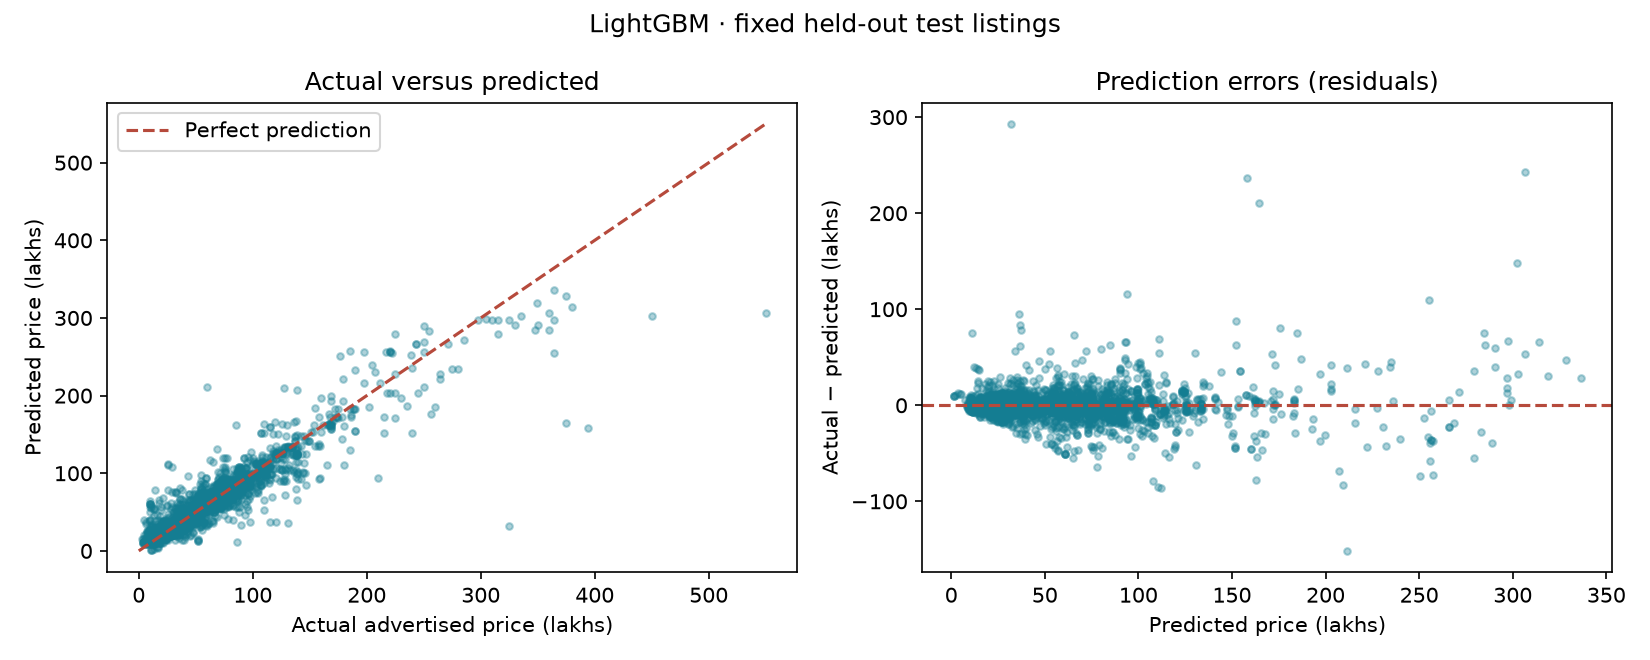

### Ridge: strengths and limitations

**Strengths.** Regularized linear reference for measuring the benefit of tree models. Simple additive structure and relatively inexpensive inference.

**Limitations.** Does not automatically learn nonlinear interactions. Extrapolation can produce unrealistic or negative prices.

**Measured results.** Validation MAE: **11.12 lakhs**; test MAE: **9.99 lakhs**; test RMSE: **20.69 lakhs**; test R²: **0.781**. Training MAE was **9.23 lakhs**. Lower MAE/RMSE is better; higher R² is better. R² is unitless, not percentage accuracy.

**Feature-importance chart.** The strongest fields are **year, brand, model, engine cc**, in that order. Longer bars mean shuffling that feature increased test error more. This is overall model reliance, not proof of causation, the direction of an effect, or an explanation for a single car. Correlated fields can share importance, and shuffling can produce unrealistic combinations.

**Actual-versus-predicted graph.** Points on the dashed diagonal are correct predictions. Points below it are underestimates; points above it are overestimates. Each point represents one unseen test listing.

**Residual graph.** Residual = actual price − predicted price. Positive values mean underestimation; negative values mean overestimation. A tight cloud around zero is desirable. The mean signed residual is **-0.39 lakhs**; the largest absolute test error is **360.61 lakhs**. These describe the whole test set, not a guaranteed range for the current vehicle.

**What the graphs show here.** Most listings form a dense cluster at the lower end of the price range, broadly following the diagonal. The diagnostics show the direction and size of errors for this model. Points far from the diagonal or zero line identify large errors; no model is guaranteed reliable across all vehicles. The plots alone do not establish why those listings were difficult.

**Large-error interpretation.** RMSE (20.69) is much larger than MAE (9.99), consistent with some large errors having a strong effect on the squared-error metric. Inspect isolated points far from the diagonal/zero line; an average score can hide these failures.


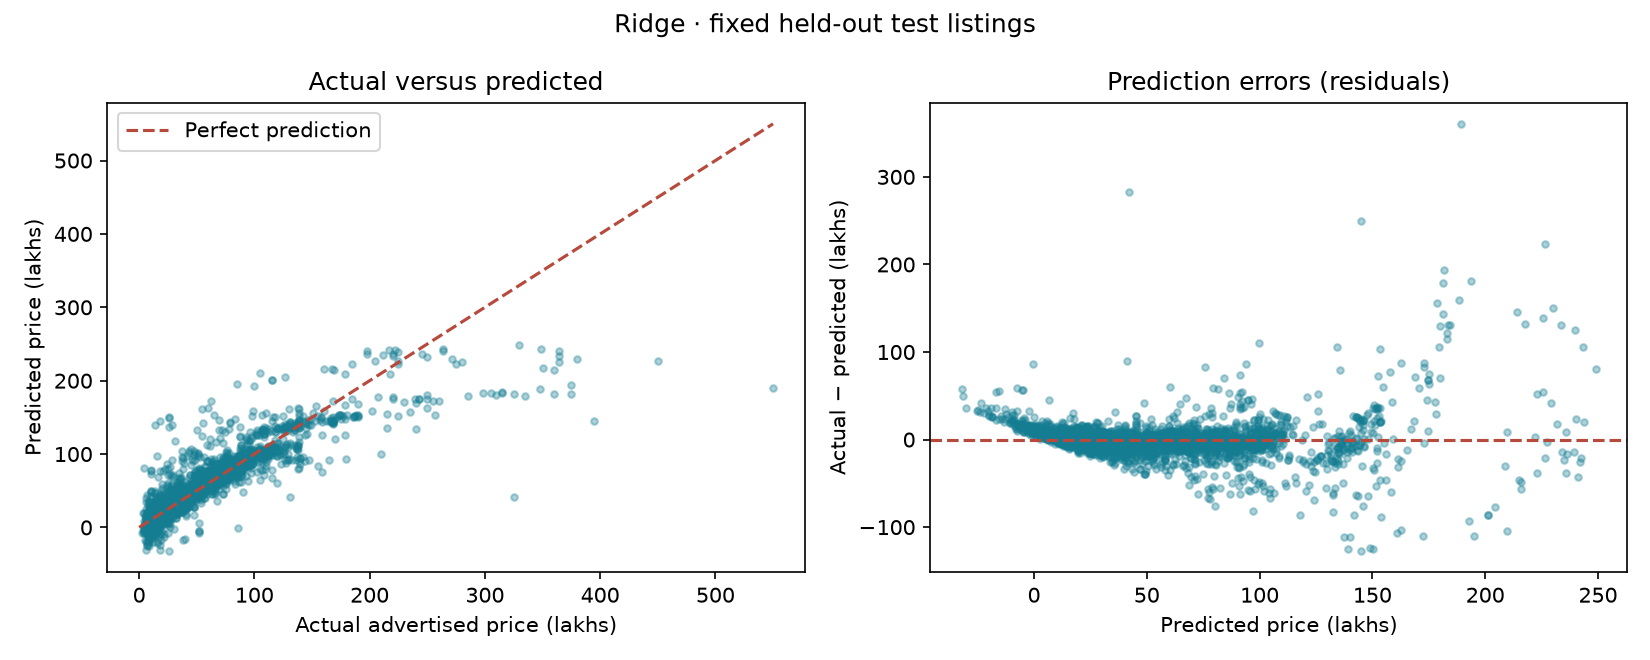

### Stacking: strengths and limitations

**Strengths.** Combines Random Forest and XGBoost predictions using Ridge. Meta-model learns from later out-of-fold predictions.

**Limitations.** Similar base-model errors can limit improvement. More training work; early rows are excluded from meta-training.

**Measured results.** Validation MAE: **7.30 lakhs**; test MAE: **6.47 lakhs**; test RMSE: **14.41 lakhs**; test R²: **0.894**. Training MAE was **4.78 lakhs**. Lower MAE/RMSE is better; higher R² is better. R² is unitless, not percentage accuracy.

**Feature-importance chart.** The strongest fields are **year, brand, engine cc, gear**, in that order. Longer bars mean shuffling that feature increased test error more. This is overall model reliance, not proof of causation, the direction of an effect, or an explanation for a single car. Correlated fields can share importance, and shuffling can produce unrealistic combinations.

**Actual-versus-predicted graph.** Points on the dashed diagonal are correct predictions. Points below it are underestimates; points above it are overestimates. Each point represents one unseen test listing.

**Residual graph.** Residual = actual price − predicted price. Positive values mean underestimation; negative values mean overestimation. A tight cloud around zero is desirable. The mean signed residual is **-0.90 lakhs**; the largest absolute test error is **296.06 lakhs**. These describe the whole test set, not a guaranteed range for the current vehicle.

**What the graphs show here.** Most listings form a dense cluster at the lower end of the price range, broadly following the diagonal. The diagnostics show the direction and size of errors for this model. Points far from the diagonal or zero line identify large errors; no model is guaranteed reliable across all vehicles. The plots alone do not establish why those listings were difficult.

**Large-error interpretation.** RMSE (14.41) is much larger than MAE (6.47), consistent with some large errors having a strong effect on the squared-error metric. Inspect isolated points far from the diagonal/zero line; an average score can hide these failures.


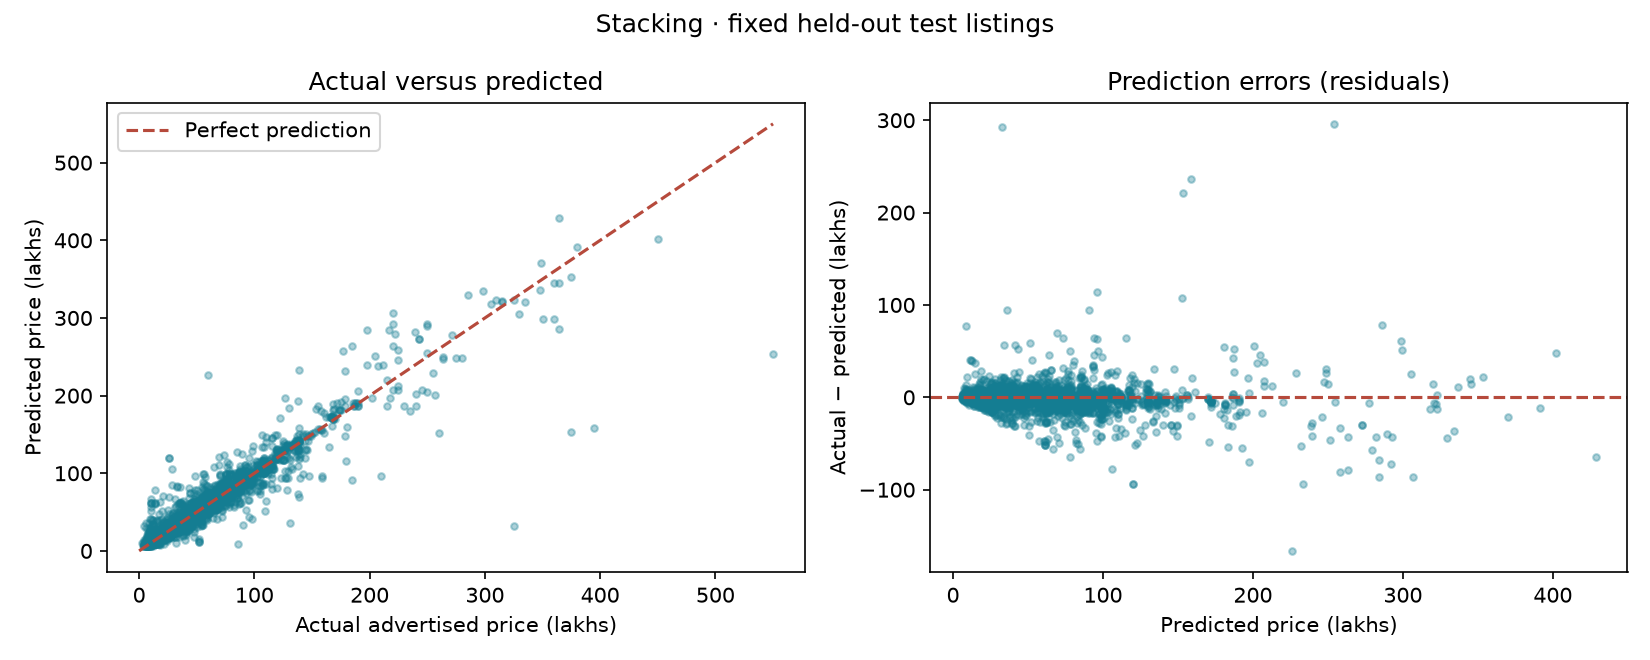

In [5]:
metadata=json.loads((ROOT/'models/metadata.json').read_text())
for name in metadata['models']:
    slug=name.lower().replace(' ','_')
    display(Markdown((ROOT/f'reports/interpretations/interpretation_{slug}.md').read_text()))
    display(Image(filename=str(ROOT/f'reports/figures/diagnostics_{slug}.png')))

## Reload all models and infer the reserved sample

In [6]:
from src.predict import predict, load_artifacts
example=json.loads((ROOT/'models/demo.json').read_text())
display(example['input'])
for name in metadata['models']:
    display(predict(example['input'],*load_artifacts(name)))
print('Actual price (lakhs):',example['actual'])

{'year': 2020,
 'engine_cc': 1000.0,
 'brand': 'ZOTYE',
 'model': 'Z100',
 'gear': 'MANUAL',
 'fuel': 'PETROL',
 'town': 'PANADURA',
 'leasing': 'NO LEASING',
 'condition': 'USED',
 'air_condition': 'AVAILABLE',
 'power_steering': 'AVAILABLE',
 'power_mirror': 'AVAILABLE',
 'power_window': 'AVAILABLE'}

{'prediction': 29.962546221129287,
 'unit': 'LKR lakhs',
 'prediction_lkr': 2996254.622112929,
 'currency': 'LKR',
 'warnings': [],
 'model': 'Random Forest'}

{'prediction': 32.076656341552734,
 'unit': 'LKR lakhs',
 'prediction_lkr': 3207665.6341552734,
 'currency': 'LKR',
 'warnings': [],
 'model': 'XGBoost'}

{'prediction': 31.866303508535122,
 'unit': 'LKR lakhs',
 'prediction_lkr': 3186630.350853512,
 'currency': 'LKR',
 'warnings': [],
 'model': 'CatBoost'}

{'prediction': 28.213395104954753,
 'unit': 'LKR lakhs',
 'prediction_lkr': 2821339.5104954755,
 'currency': 'LKR',
 'warnings': [],
 'model': 'LightGBM'}

{'prediction': 29.0413630593156,
 'unit': 'LKR lakhs',
 'prediction_lkr': 2904136.30593156,
 'currency': 'LKR',
 'warnings': [],
 'model': 'Ridge'}

{'prediction': 33.507657330283195,
 'unit': 'LKR lakhs',
 'prediction_lkr': 3350765.7330283197,
 'currency': 'LKR',
 'warnings': [],
 'model': 'Stacking'}

Actual price (lakhs): 30.95


## Application and reproducibility
Run `streamlit run app/app.py`. See README for the deployed application, reproduction commands and access information.